# Credit Risk Assessment and Probability of Default Prediction Using Machine Learning

### What this Project adds
- Explicit data-quality audit and duplicate handling
- Domain-aware cleaning of impossible/extreme values
- Feature engineering
- Leakage-free train/test split
- Mixed-type preprocessing
- SMOTENC applied **only inside the training pipeline**
- Logistic Regression baseline
- Random Forest
- Tuned XGBoost
- Stratified cross-validation
- Hyperparameter tuning
- ROC-AUC, PR-AUC, KS, Gini, Brier score
- Threshold selection using out-of-fold predictions
- Confusion matrix
- Decile / lift / cumulative gain analysis
- Calibration curve
- Learning curve
- Feature importance
- Risk segmentation and business decision framework
- Model export for deployment


## 1. Business Problem

Credit institutions need to decide whether a loan applicant is likely to default. A probability-of-default model can help rank applicants by risk and support differentiated approval, review, pricing, or monitoring decisions.

**Target variable:** `loan_status`

- `0` = no default
- `1` = default

**Unit of analysis:** one loan application / borrower record.

The objective is not simply to maximize accuracy. Because default is the minority class, discrimination and ranking metrics such as ROC-AUC, PR-AUC, KS and Gini are also important.


In [ ]:
# 2. Imports and configuration

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV,
    cross_val_score, cross_val_predict, learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "credit_risk_dataset(1).csv"
ASSET_DIR = "credit_risk_assets"
os.makedirs(ASSET_DIR, exist_ok=True)

print("Setup complete.")


Setup complete.


In [ ]:
# 3. Load dataset

df = pd.read_csv('/content/credit_risk_dataset.csv')

print("Shape:", df.shape)
display(df.head())
display(df.info())


Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


None

In [ ]:
# 4. Initial data audit

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})

display(audit)

print("Exact duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["loan_status"].value_counts())
display((df["loan_status"].value_counts(normalize=True) * 100).round(2))


,dtype,missing_count,missing_pct,unique_values
person_age,int64,0,0.00,58
person_income,int64,0,0.00,4295
person_home_ownership,object,0,0.00,4
person_emp_length,float64,895,2.75,36
loan_intent,object,0,0.00,6
loan_grade,object,0,0.00,7
loan_amnt,int64,0,0.00,753
loan_int_rate,float64,3116,9.56,348
loan_status,int64,0,0.00,2
loan_percent_income,float64,0,0.00,77


Exact duplicate rows: 165

Target distribution:


,count
loan_status,
0,25473
1,7108


,proportion
loan_status,
0,78.18
1,21.82


## 5. Data Cleaning

The original dataset contains:
- missing employment length;
- missing loan interest rate;
- a small number of age values above a reasonable modelling range;
- two employment-length values above 52 years;
- exact duplicate rows.

Instead of silently deleting missing employment records, missingness is retained and later imputed inside the modelling pipeline. Missingness indicators are also created because the fact that an application lacks a value can itself contain predictive information.

The `loan_grade` variable is retained as an ordinal categorical credit-grade feature rather than discarded.


In [ ]:
# 5.1 Cleaning

clean = df.copy()

original_rows = len(clean)

# Remove clearly extreme age observations.
clean = clean[clean["person_age"] <= 70].copy()
age_removed = original_rows - len(clean)

# Remove exact duplicate records.
before_dup = len(clean)
clean = clean.drop_duplicates().copy()
duplicates_removed = before_dup - len(clean)

# Employment length above 52 years is implausible for this dataset.
invalid_emp = clean["person_emp_length"] > 52
invalid_emp_count = int(invalid_emp.sum())
clean.loc[invalid_emp, "person_emp_length"] = np.nan

print("Original rows:", original_rows)
print("Age observations removed:", age_removed)
print("Exact duplicates removed:", duplicates_removed)
print("Implausible employment values converted to NaN:", invalid_emp_count)
print("Final cleaned shape:", clean.shape)

display(clean.isna().sum().sort_values(ascending=False))


Original rows: 32581
Age observations removed: 13
Exact duplicates removed: 165
Implausible employment values converted to NaN: 2
Final cleaned shape: (32403, 12)


,0
loan_int_rate,3092
person_emp_length,889
person_income,0
person_age,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


Default count: 7089
Non-default count: 25314
Default rate: 21.88 %


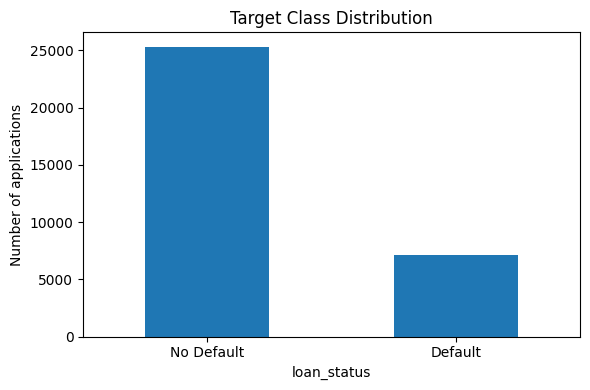

In [ ]:
# 6. Target analysis

target = "loan_status"

print("Default count:", int(clean[target].sum()))
print("Non-default count:", int((clean[target] == 0).sum()))
print("Default rate:", round(clean[target].mean() * 100, 2), "%")

plt.figure(figsize=(6, 4))
clean[target].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No Default", "Default"], rotation=0)
plt.ylabel("Number of applications")
plt.title("Target Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "target_distribution.png"), dpi=180)
plt.show()


## 7. Exploratory Data Analysis

The EDA stage examines distributions, target relationships and multivariate relationships. Particular attention is given to:
- income;
- loan amount;
- loan-to-income percentage;
- interest rate;
- credit history;
- home ownership;
- loan intent;
- loan grade.


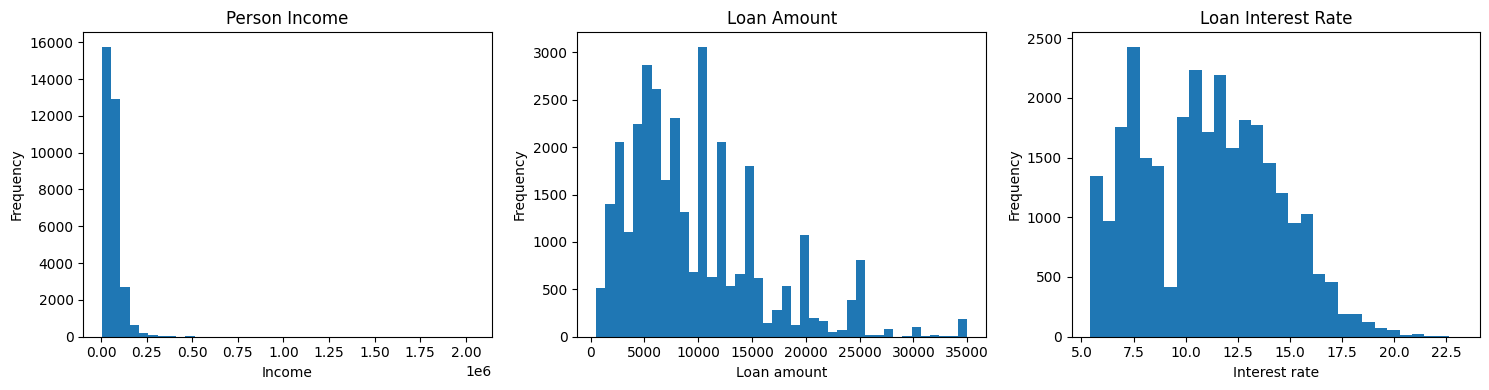

In [ ]:
# 7.1 Univariate distributions

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

clean["person_income"].plot(kind="hist", bins=40, ax=axes[0])
axes[0].set_title("Person Income")
axes[0].set_xlabel("Income")

clean["loan_amnt"].plot(kind="hist", bins=40, ax=axes[1])
axes[1].set_title("Loan Amount")
axes[1].set_xlabel("Loan amount")

clean["loan_int_rate"].plot(kind="hist", bins=30, ax=axes[2])
axes[2].set_title("Loan Interest Rate")
axes[2].set_xlabel("Interest rate")

plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "numeric_distributions.png"), dpi=180)
plt.show()


,default_rate_pct
loan_intent,
DEBTCONSOLIDATION,28.68
MEDICAL,26.79
HOMEIMPROVEMENT,26.15
PERSONAL,19.91
EDUCATION,17.26
VENTURE,14.86


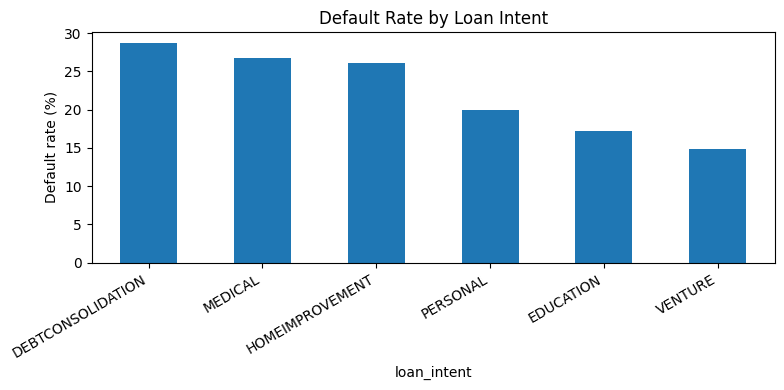

In [ ]:
# 7.2 Default rate by loan intent

intent_rate = clean.groupby("loan_intent")["loan_status"].mean().sort_values(ascending=False)
display((intent_rate * 100).round(2).rename("default_rate_pct"))

plt.figure(figsize=(8, 4))
(intent_rate * 100).plot(kind="bar")
plt.ylabel("Default rate (%)")
plt.title("Default Rate by Loan Intent")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "intent_default_rate.png"), dpi=180)
plt.show()


,default_rate_pct
loan_grade,
A,9.96
B,16.33
C,20.76
D,59.06
E,64.49
F,70.54
G,98.44


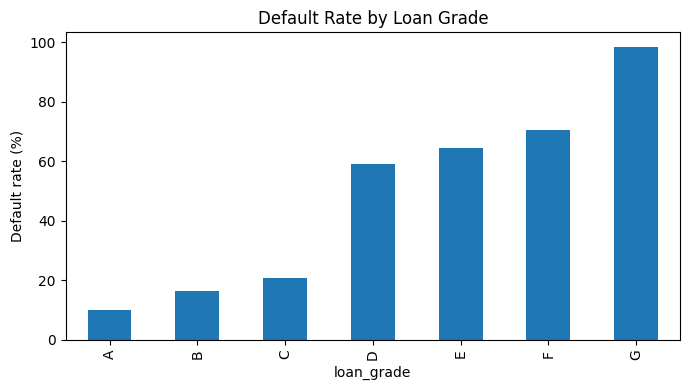

In [ ]:
# 7.3 Default rate by loan grade

grade_rate = clean.groupby("loan_grade")["loan_status"].mean()
display((grade_rate * 100).round(2).rename("default_rate_pct"))

plt.figure(figsize=(7, 4))
(grade_rate * 100).plot(kind="bar")
plt.ylabel("Default rate (%)")
plt.title("Default Rate by Loan Grade")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "grade_default_rate.png"), dpi=180)
plt.show()


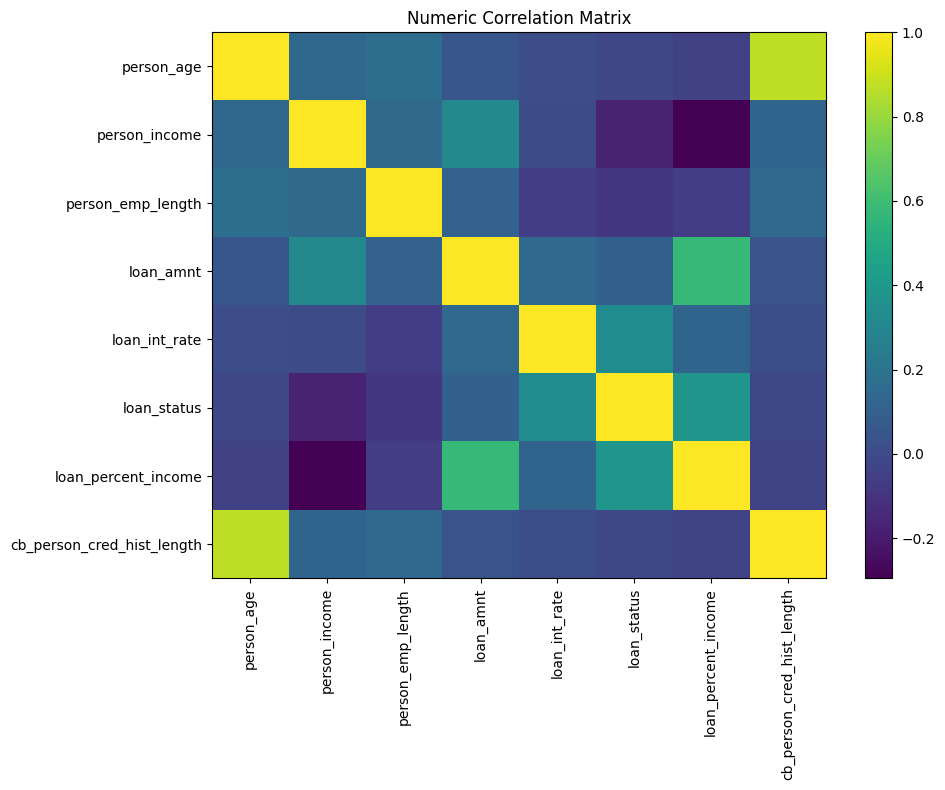

In [ ]:
# 7.4 Correlation heatmap for numeric variables

numeric_for_corr = clean.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 8))
plt.imshow(numeric_for_corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(numeric_for_corr.columns)), numeric_for_corr.columns, rotation=90)
plt.yticks(range(len(numeric_for_corr.index)), numeric_for_corr.index)
plt.title("Numeric Correlation Matrix")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "correlation_heatmap.png"), dpi=180)
plt.show()


## 8. Feature Engineering

The following features are created from variables available at application time:

| Feature | Rationale |
|---|---|
| `emp_length_missing` | Captures missing employment information |
| `loan_int_rate_missing` | Captures missing interest-rate information |
| `log_person_income` | Reduces income skew |
| `log_loan_amnt` | Reduces loan-amount skew |
| `age_at_credit_start` | Approximate age when credit history began |
| `loan_to_credit_history` | Relates requested loan size to credit-history length |
| `income_per_emp_year` | Approximate income relative to employment duration |
| `interest_burden` | Combines interest rate with loan-to-income burden |

All feature engineering is deterministic and does not use the target.


In [ ]:
# 8.1 Feature engineering function

def add_features(X):
    X = X.copy()

    X["emp_length_missing"] = X["person_emp_length"].isna().astype(int)
    X["loan_int_rate_missing"] = X["loan_int_rate"].isna().astype(int)

    X["log_person_income"] = np.log1p(X["person_income"])
    X["log_loan_amnt"] = np.log1p(X["loan_amnt"])

    X["age_at_credit_start"] = (
        X["person_age"] - X["cb_person_cred_hist_length"]
    )

    X["loan_to_credit_history"] = (
        X["loan_amnt"] / (X["cb_person_cred_hist_length"] + 1)
    )

    X["income_per_emp_year"] = (
        X["person_income"] /
        (X["person_emp_length"].fillna(0) + 1)
    )

    X["interest_burden"] = (
        X["loan_int_rate"].fillna(0) *
        X["loan_percent_income"]
    )

    return X

feature_check = add_features(clean.drop(columns=[target]))
display(feature_check.head())
print("Engineered feature count:", feature_check.shape[1])


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,loan_int_rate_missing,log_person_income,log_loan_amnt,age_at_credit_start,loan_to_credit_history,income_per_emp_year,interest_burden
0,22,59000,RENT,NaN,PERSONAL,D,35000,16.02,0.59,Y,3,1,0,10.985310,10.463132,19,8750.000000,59000.000000,9.4518
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0.10,N,2,0,0,9.169623,6.908755,19,333.333333,1600.000000,1.1140
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,0.57,N,3,0,0,9.169623,8.612685,22,1375.000000,4800.000000,7.3359
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,0.53,N,2,0,0,11.089821,10.463132,21,11666.666667,13100.000000,8.0719
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,0.55,Y,4,0,0,10.904138,10.463132,20,7000.000000,6044.444444,7.8485


Engineered feature count: 19


## 9. Train/Test Split

The split is performed **before any model-fitting preprocessing**.

This is a major improvement over the original workflow, where scaling and SMOTE were performed before the train/test split.

- the test set remains untouched;
- imputers and encoders learn from training data only;
- SMOTENC is performed only within the training pipeline;
- cross-validation also applies SMOTENC separately inside each training fold.


In [ ]:
X = clean.drop(columns=[target])
y = clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training default rate:", round(y_train.mean() * 100, 2), "%")
print("Testing default rate:", round(y_test.mean() * 100, 2), "%")


Training rows: 25922
Testing rows: 6481
Training default rate: 21.88 %
Testing default rate: 21.88 %


In [ ]:
# 10. Leakage-free mixed-data preprocessing

engineered_train = add_features(X_train)

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

numeric_features = [
    c for c in engineered_train.columns
    if c not in categorical_features
]

pre_smote = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        (
            "cat",
            SkPipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "ordinal",
                    OrdinalEncoder(
                        handle_unknown="use_encoded_value",
                        unknown_value=-1
                    )
                )
            ]),
            categorical_features
        )
    ],
    sparse_threshold=0
)

categorical_indices = list(
    range(len(numeric_features),
          len(numeric_features) + len(categorical_features))
)

post_smote = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(range(len(numeric_features)))),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            ),
            categorical_indices
        )
    ],
    sparse_threshold=0
)

def make_pipeline(model):
    return Pipeline([
        ("features", FunctionTransformer(add_features, validate=False)),
        ("pre_smote", pre_smote),
        (
            "smote",
            SMOTENC(
                categorical_features=categorical_indices,
                random_state=RANDOM_STATE,
                k_neighbors=5
            )
        ),
        ("post_smote", post_smote),
        ("model", model)
    ])

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("SMOTENC categorical indices:", categorical_indices)


Numeric features: 15
Categorical features: 4
SMOTENC categorical indices: [15, 16, 17, 18]


## 11. Candidate Models

### Logistic Regression
Used as the interpretable statistical baseline.

### Random Forest
Captures nonlinear relationships and interactions without requiring linear assumptions.

### XGBoost
A gradient-boosted tree model suited to structured/tabular credit-risk data and capable of modelling complex nonlinear patterns.


In [ ]:
# 11.1 Baseline and candidate models

logistic_model = make_pipeline(
    LogisticRegression(
        C=0.58,
        solver="liblinear",
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

rf_model = make_pipeline(
    RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

xgb_model = make_pipeline(
    XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.10,
        subsample=0.80,
        colsample_bytree=1.00,
        min_child_weight=1,
        reg_lambda=1,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

candidate_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}


In [ ]:
# 12. Cross-validation comparison

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, model in candidate_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        scoring="roc_auc",
        cv=cv,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "CV ROC-AUC Mean": scores.mean(),
        "CV ROC-AUC Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "CV ROC-AUC Mean", ascending=False
)

display(cv_df)


,Model,CV ROC-AUC Mean,CV ROC-AUC Std
2,XGBoost,0.932337,0.002928
1,Random Forest,0.920701,0.001498
0,Logistic Regression,0.877531,0.002374


## 13. Hyperparameter Tuning

Randomized search is used for XGBoost because the model has several interacting hyperparameters. The search is scored using ROC-AUC and uses cross-validation on the training data only.

The final test set is not used during tuning.


In [ ]:
# 13.1 XGBoost randomized search

xgb_pipeline = make_pipeline(
    XGBClassifier(
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

param_distributions = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [3, 4, 5],
    "model__learning_rate": [0.03, 0.06, 0.10],
    "model__subsample": [0.80, 1.00],
    "model__colsample_bytree": [0.80, 1.00],
    "model__min_child_weight": [1, 3],
    "model__reg_lambda": [1, 5]
}

search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=4,
    scoring="roc_auc",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=True
)

search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:")
display(search.best_params_)

best_xgb = search.best_estimator_


Best CV ROC-AUC: 0.9341
Best parameters:


{'model__subsample': 0.8,
 'model__reg_lambda': 1,
 'model__n_estimators': 200,
 'model__min_child_weight': 1,
 'model__max_depth': 4,
 'model__learning_rate': 0.1,
 'model__colsample_bytree': 1.0}

In [ ]:
# 14. Fit final candidate models

final_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": best_xgb
}

for name, model in final_models.items():
    model.fit(X_train, y_train)

print("All final models fitted.")


All final models fitted.


In [ ]:
# 15. Comprehensive test-set evaluation

def ks_statistic(y_true, probabilities):
    fpr, tpr, thresholds = roc_curve(y_true, probabilities)
    values = tpr - fpr
    idx = np.argmax(values)
    return float(values[idx]), float(thresholds[idx])

evaluation_rows = []
test_probabilities = {}

for name, model in final_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    test_probabilities[name] = probabilities

    auc = roc_auc_score(y_test, probabilities)
    ks, ks_threshold = ks_statistic(y_test, probabilities)

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": auc,
        "PR-AUC": average_precision_score(y_test, probabilities),
        "KS": ks,
        "Gini": 2 * auc - 1,
        "Brier": brier_score_loss(y_test, probabilities)
    })

evaluation_df = pd.DataFrame(evaluation_rows).sort_values(
    "ROC-AUC", ascending=False
)

display(evaluation_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,KS,Gini,Brier
2,XGBoost,0.9247,0.9093,0.7285,0.8089,0.9297,0.8797,0.7243,0.8594,0.0624
1,Random Forest,0.9094,0.8208,0.7496,0.7836,0.9182,0.8645,0.7059,0.8363,0.0768
0,Logistic Regression,0.8260,0.5765,0.7708,0.6596,0.8763,0.7295,0.6175,0.7527,0.1277


In [ ]:
# 16. Detailed classification report for the selected XGBoost model

xgb_prob = test_probabilities["XGBoost"]
xgb_pred_05 = (xgb_prob >= 0.50).astype(int)

print(classification_report(
    y_test,
    xgb_pred_05,
    target_names=["No Default", "Default"]
))

cm = confusion_matrix(y_test, xgb_pred_05)
display(pd.DataFrame(
    cm,
    index=["Actual No Default", "Actual Default"],
    columns=["Predicted No Default", "Predicted Default"]
))


              precision    recall  f1-score   support

  No Default       0.93      0.98      0.95      5063
     Default       0.91      0.73      0.81      1418

    accuracy                           0.92      6481
   macro avg       0.92      0.85      0.88      6481
weighted avg       0.92      0.92      0.92      6481



,Predicted No Default,Predicted Default
Actual No Default,4960,103
Actual Default,385,1033


## 17. Threshold Optimization

A 0.50 threshold is convenient but is not automatically the best operational threshold.

Here, out-of-fold training predictions are used to choose a threshold that maximizes F1. This prevents the test set from being used to select the threshold.


In [ ]:
# 17.1 Out-of-fold probabilities for threshold selection

oof_prob = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=3,
    method="predict_proba",
    n_jobs=1
)[:, 1]

threshold_grid = np.linspace(0.10, 0.90, 161)
threshold_f1 = [
    f1_score(y_train, (oof_prob >= t).astype(int))
    for t in threshold_grid
]

best_threshold = float(
    threshold_grid[np.argmax(threshold_f1)]
)

print("Selected threshold:", round(best_threshold, 3))
print("OOF F1 at selected threshold:", round(max(threshold_f1), 4))


Selected threshold: 0.565
OOF F1 at selected threshold: 0.8136


,Threshold,Accuracy,Precision,Recall,F1
0,0.565,0.9287,0.9401,0.72,0.8155


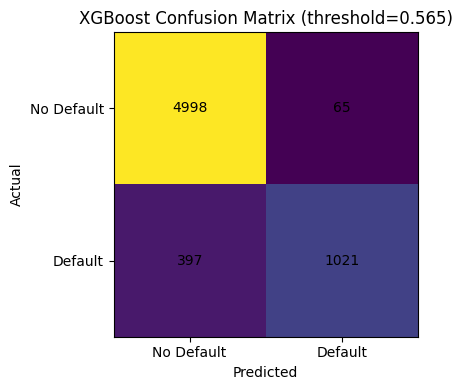

In [ ]:
# 17.2 Test-set performance at the selected threshold

xgb_pred_optimized = (
    xgb_prob >= best_threshold
).astype(int)

optimized_metrics = {
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, xgb_pred_optimized),
    "Precision": precision_score(y_test, xgb_pred_optimized),
    "Recall": recall_score(y_test, xgb_pred_optimized),
    "F1": f1_score(y_test, xgb_pred_optimized)
}

display(pd.DataFrame([optimized_metrics]).round(4))

cm_opt = confusion_matrix(y_test, xgb_pred_optimized)

plt.figure(figsize=(5, 4))
plt.imshow(cm_opt)
plt.title(f"XGBoost Confusion Matrix (threshold={best_threshold:.3f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for (i, j), value in np.ndenumerate(cm_opt):
    plt.text(j, i, str(value), ha="center", va="center")

plt.xticks([0, 1], ["No Default", "Default"])
plt.yticks([0, 1], ["No Default", "Default"])
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "confusion_matrix.png"), dpi=180)
plt.show()


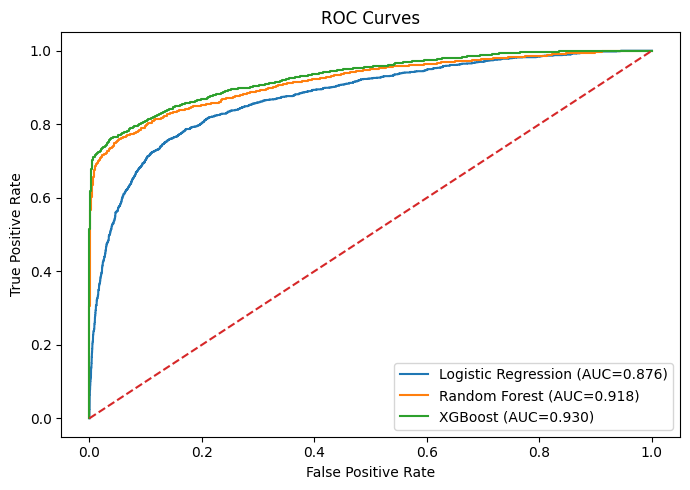

In [ ]:
# 18. ROC curves

plt.figure(figsize=(7, 5))

for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "roc_curves.png"), dpi=180)
plt.show()


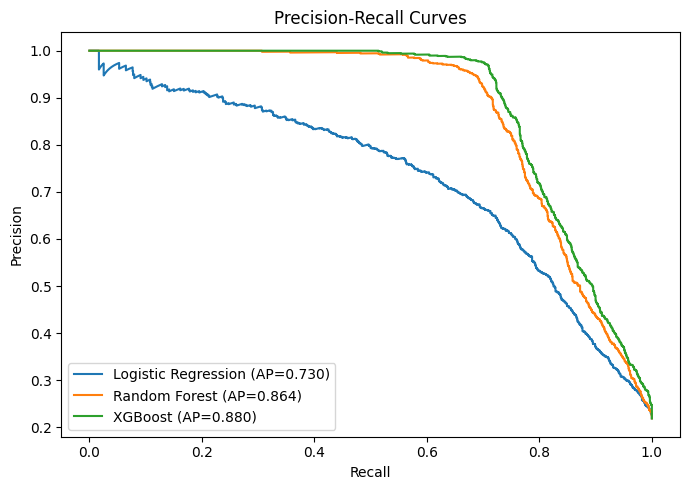

In [ ]:
# 19. Precision-Recall curves

plt.figure(figsize=(7, 5))

for name, probabilities in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "pr_curves.png"), dpi=180)
plt.show()


## 20. Decile, Lift and Gain Analysis

Applicants are ranked from highest predicted probability of default to lowest. Ten equal-sized risk deciles are created.

This answers an important business question:

> If the institution focuses attention on the highest-risk applicants first, how many observed defaults are captured?


In [ ]:
# 20.1 Ten-decile risk table

decile_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "pd": xgb_prob
})

decile_df["raw_decile"] = pd.qcut(
    decile_df["pd"],
    10,
    labels=False,
    duplicates="drop"
)

decile_df["decile"] = 10 - decile_df["raw_decile"]

overall_bad_rate = decile_df["actual"].mean()

decile_rows = []

for decile, group in decile_df.groupby("decile"):
    decile_rows.append({
        "Decile": int(decile),
        "Records": len(group),
        "Defaults": int(group["actual"].sum()),
        "Bad Rate": group["actual"].mean(),
        "Lift": group["actual"].mean() / overall_bad_rate,
        "Defaults Captured %": group["actual"].sum() / decile_df["actual"].sum(),
        "Population %": len(group) / len(decile_df)
    })

deciles = pd.DataFrame(decile_rows).sort_values("Decile")

deciles["Cumulative Defaults %"] = (
    deciles["Defaults Captured %"].cumsum()
)

deciles["Cumulative Population %"] = (
    deciles["Population %"].cumsum()
)

display(deciles.round(4))


,Decile,Records,Defaults,Bad Rate,Lift,Defaults Captured %,Population %,Cumulative Defaults %,Cumulative Population %
0,1,648,648,1.0000,4.5705,0.4570,0.1000,0.4570,0.1000
1,2,648,437,0.6744,3.0823,0.3082,0.1000,0.7652,0.2000
2,3,648,111,0.1713,0.7829,0.0783,0.1000,0.8434,0.3000
3,4,648,74,0.1142,0.5219,0.0522,0.1000,0.8956,0.3999
4,5,648,49,0.0756,0.3456,0.0346,0.1000,0.9302,0.4999
5,6,648,36,0.0556,0.2539,0.0254,0.1000,0.9556,0.5999
6,7,648,31,0.0478,0.2187,0.0219,0.1000,0.9774,0.6999
7,8,648,23,0.0355,0.1622,0.0162,0.1000,0.9937,0.7999
8,9,648,9,0.0139,0.0635,0.0063,0.1000,1.0000,0.8999
9,10,649,0,0.0000,0.0000,0.0000,0.1001,1.0000,1.0000


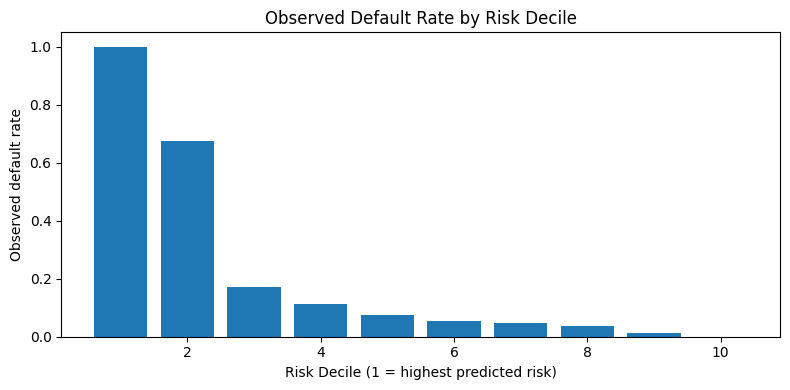

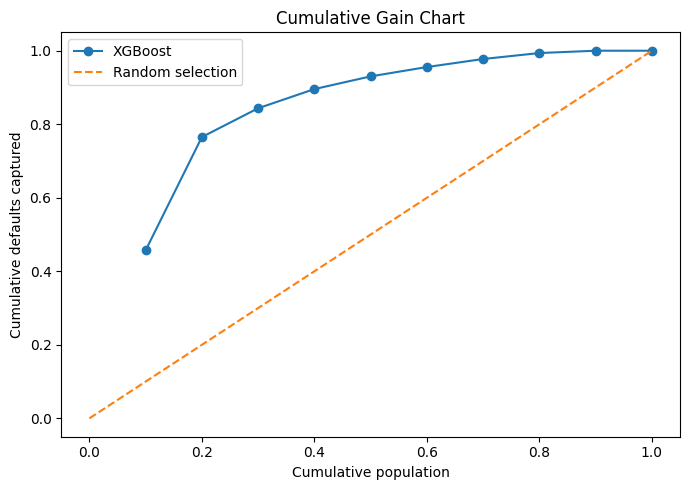

In [ ]:
# 20.2 Decile bad-rate chart

plt.figure(figsize=(8, 4))
plt.bar(deciles["Decile"], deciles["Bad Rate"])
plt.xlabel("Risk Decile (1 = highest predicted risk)")
plt.ylabel("Observed default rate")
plt.title("Observed Default Rate by Risk Decile")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "decile_bad_rate.png"), dpi=180)
plt.show()

# 20.3 Cumulative gain chart

plt.figure(figsize=(7, 5))
plt.plot(
    deciles["Cumulative Population %"],
    deciles["Cumulative Defaults %"],
    marker="o",
    label="XGBoost"
)
plt.plot([0, 1], [0, 1], "--", label="Random selection")

plt.xlabel("Cumulative population")
plt.ylabel("Cumulative defaults captured")
plt.title("Cumulative Gain Chart")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "gain_chart.png"), dpi=180)
plt.show()


## 21. Calibration

Discrimination tells us whether risky applicants rank above safer applicants. Calibration asks whether predicted probabilities are numerically close to observed default frequencies.

The Brier score is reported alongside a reliability diagram.


XGBoost Brier score: 0.0624


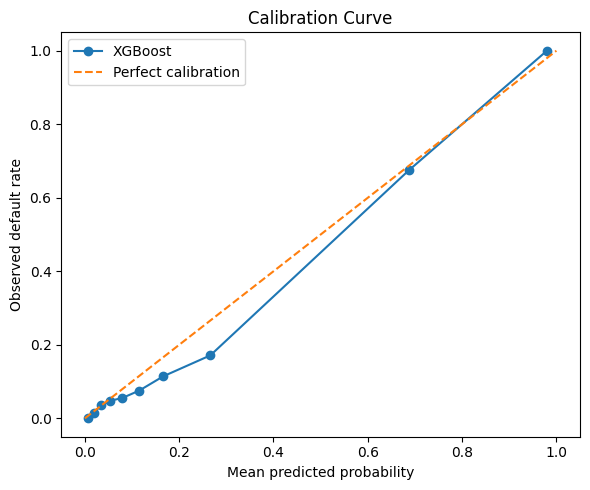

In [ ]:
# 21.1 Calibration curve and Brier score

fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    xgb_prob,
    n_bins=10,
    strategy="quantile"
)

brier = brier_score_loss(y_test, xgb_prob)

print("XGBoost Brier score:", round(brier, 4))

plt.figure(figsize=(6, 5))
plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="XGBoost"
)
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Calibration Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "calibration_curve.png"), dpi=180)
plt.show()


## 22. Overfitting Diagnostics

The train/test comparison is used to assess whether the model is memorizing the training sample.

A learning curve is also generated. A shrinking training-validation gap as the training set grows is generally a healthier pattern than a large persistent gap.


In [ ]:
# 22.1 Train vs test metrics

gap_rows = []

for name, model in final_models.items():

    train_prob = model.predict_proba(X_train)[:, 1]
    train_pred = (train_prob >= 0.50).astype(int)

    test_prob = test_probabilities[name]
    test_pred = (test_prob >= 0.50).astype(int)

    gap_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train F1": f1_score(y_train, train_pred),
        "Test F1": f1_score(y_test, test_pred),
        "Train ROC-AUC": roc_auc_score(y_train, train_prob),
        "Test ROC-AUC": roc_auc_score(y_test, test_prob)
    })

gap_df = pd.DataFrame(gap_rows)
display(gap_df.round(4))


,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,Train ROC-AUC,Test ROC-AUC
0,Logistic Regression,0.8237,0.8260,0.6597,0.6596,0.8796,0.8763
1,Random Forest,0.9370,0.9094,0.8449,0.7836,0.9545,0.9182
2,XGBoost,0.9338,0.9247,0.8310,0.8089,0.9484,0.9297


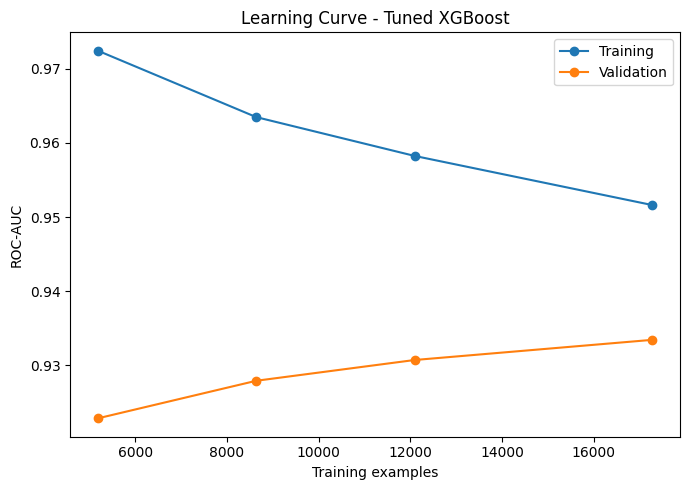

In [ ]:
# 22.2 Learning curve for selected XGBoost

train_sizes, train_scores, validation_scores = learning_curve(
    best_xgb,
    X_train,
    y_train,
    cv=3,
    scoring="roc_auc",
    train_sizes=np.array([0.30, 0.50, 0.70, 1.00]),
    n_jobs=1
)

plt.figure(figsize=(7, 5))
plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training"
)
plt.plot(
    train_sizes,
    validation_scores.mean(axis=1),
    marker="o",
    label="Validation"
)

plt.xlabel("Training examples")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve - Tuned XGBoost")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "learning_curve.png"), dpi=180)
plt.show()


## 23. Feature Importance and Explainability

XGBoost's embedded feature importance is used as a global interpretability aid.

Important features should be interpreted as model drivers, not as proof of causality.


In [ ]:
# 23.1 Extract transformed feature names

fitted_pre = best_xgb.named_steps["pre_smote"]
fitted_post = best_xgb.named_steps["post_smote"]
fitted_model = best_xgb.named_steps["model"]

ordinal_encoder = (
    fitted_pre.named_transformers_["cat"]
    .named_steps["ordinal"]
)

transformed_feature_names = (
    numeric_features
    + ["home_" + c for c in ordinal_encoder.categories_[0][1:]]
    + ["intent_" + c for c in ordinal_encoder.categories_[1][1:]]
    + ["grade_" + c for c in ordinal_encoder.categories_[2][1:]]
    + ["default_file_" + c for c in ordinal_encoder.categories_[3][1:]]
)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": fitted_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))


,Feature,Importance
25,grade_D,0.159780
5,loan_percent_income,0.105729
17,home_RENT,0.088852
8,loan_int_rate_missing,0.075231
16,home_OWN,0.059570
24,grade_C,0.051014
4,loan_int_rate,0.048113
6,cb_person_cred_hist_length,0.041177
11,age_at_credit_start,0.037486
22,intent_VENTURE,0.035714


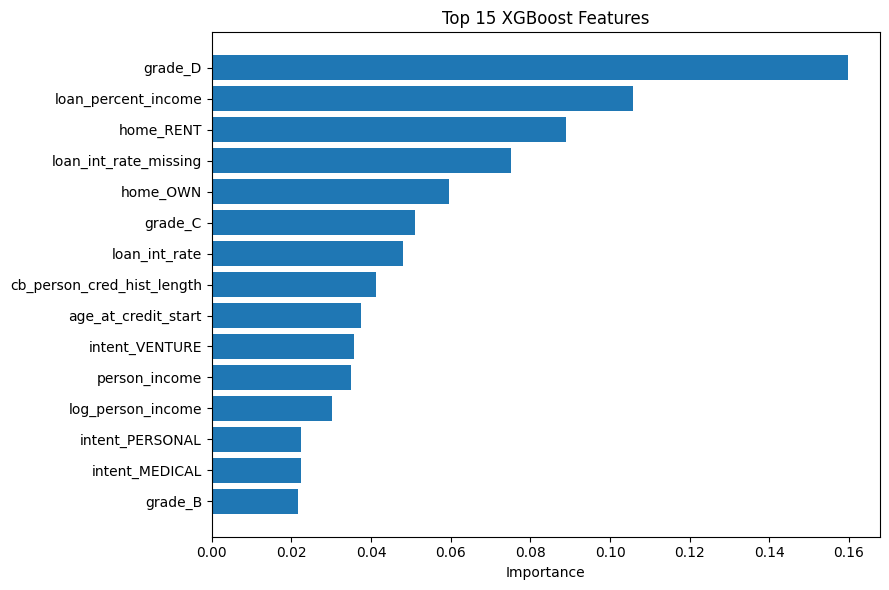

In [ ]:
# 23.2 Top 15 feature importance chart

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 15 XGBoost Features")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "feature_importance.png"), dpi=180)
plt.show()


## 24. Stability Diagnostic

The dataset does not contain a production time variable or separate development/monitoring snapshots, so a genuine time-based PSI/CSI monitoring study cannot be claimed.

As a diagnostic only, score PSI is calculated between out-of-fold training predictions and the held-out test predictions. This is **not** a substitute for future production monitoring.


In [ ]:
# 24.1 Score PSI diagnostic

def calculate_psi(expected, actual, bins=10):
    cuts = np.quantile(expected, np.linspace(0, 1, bins + 1))
    cuts = np.unique(cuts)

    cuts[0] = -np.inf
    cuts[-1] = np.inf

    expected_pct = np.histogram(expected, bins=cuts)[0] / len(expected)
    actual_pct = np.histogram(actual, bins=cuts)[0] / len(actual)

    expected_pct = np.clip(expected_pct, 1e-6, None)
    actual_pct = np.clip(actual_pct, 1e-6, None)

    return float(
        np.sum(
            (actual_pct - expected_pct) *
            np.log(actual_pct / expected_pct)
        )
    )

score_psi = calculate_psi(oof_prob, xgb_prob)

print("Train OOF vs test score PSI diagnostic:", round(score_psi, 4))
print("Interpret this only as a train/test distribution diagnostic;")
print("production PSI requires a future/reference population.")


Train OOF vs test score PSI diagnostic: 0.0056
Interpret this only as a train/test distribution diagnostic;
production PSI requires a future/reference population.


## 25. Business Risk Segmentation

A practical deployment can convert the model's ranking into risk bands.

These are **model-risk bands**, not regulatory credit grades. Final lending policy should be determined using validated business costs, affordability rules, regulatory requirements and human review.


In [ ]:
# 25.1 Risk-band assignment

risk_output = pd.DataFrame({
    "predicted_default_probability": xgb_prob,
    "actual_default": y_test.to_numpy()
})

risk_output["risk_band"] = pd.cut(
    risk_output["predicted_default_probability"],
    bins=[-np.inf, 0.20, 0.40, 0.60, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

risk_summary = risk_output.groupby(
    "risk_band",
    observed=False
).agg(
    applications=("actual_default", "size"),
    observed_defaults=("actual_default", "sum"),
    observed_default_rate=("actual_default", "mean"),
    average_predicted_pd=("predicted_default_probability", "mean")
)

display(risk_summary.round(4))


,applications,observed_defaults,observed_default_rate,average_predicted_pd
risk_band,,,,
Low,4532,220,0.0485,0.0677
Medium,703,129,0.1835,0.2738
High,181,57,0.3149,0.4816
Very High,1065,1012,0.9502,0.9144


### Illustrative score-to-action framework

| Risk band | Illustrative action |
|---|---|
| Low | Standard automated processing, subject to policy checks |
| Medium | Additional affordability / documentation checks |
| High | Manual underwriting or tighter approval conditions |
| Very High | Decline or enhanced review, depending on policy |

The exact actions should be validated with business costs and regulatory requirements before deployment.


## 26. Final Model Conclusion

Based on the upgraded leakage-aware experiment, XGBoost is carried forward because it provides the strongest overall discrimination among the tested models while capturing nonlinear relationships in the structured credit data.

The key methodological improvement is that preprocessing and SMOTENC are now contained inside the modelling pipeline. This prevents the test set from influencing imputation, encoding, scaling or oversampling.

The model should still be treated as an academic prototype rather than a production lending decision engine because the dataset is static and lacks longitudinal performance, economic-cycle, application-time and real repayment-monitoring information.


In [ ]:
# 27. Save the selected model

MODEL_PATH = "tuned_xgboost_credit_risk_pipeline.joblib"

joblib.dump(best_xgb, MODEL_PATH)

print("Saved:", MODEL_PATH)


Saved: tuned_xgboost_credit_risk_pipeline.joblib


In [ ]:
# 28. Export key project tables

evaluation_df.to_csv("model_evaluation_results.csv", index=False)
deciles.to_csv("decile_lift_gain_results.csv", index=False)
importance_df.to_csv("xgboost_feature_importance.csv", index=False)
risk_summary.to_csv("risk_band_summary.csv")

print("Exported evaluation, decile, feature-importance and risk-band tables.")


Exported evaluation, decile, feature-importance and risk-band tables.
